### SIMULACIONES DE MONTE CARLO

#### 01. IMPORTACIÓN DE LIBRERÍAS

Se importan numpy para la parte matemática de las simulaciones, os para guardar los datos sintéticos en el directorio correcto y matplotlib para graficar las simulaciones.

In [3]:
import numpy as np
import os
import matplotlib.pyplot as plt

#### 02. DATOS FIJOS DE LAS SIMULACIONES

Se determinan los siguientes datos para las simulaciones:
* T: Cantidad de periodos de madurez de la opción. 5 años según la descripción tecnica del reto.
* n_trayectories: Cantidad de trayectorias que se simularán con Monte Carlo. 100.000 trayectorias según la descripción técnica del reto.
* n_times: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar la madurez. 21 intervalos, 20 según la descripción técnica del reto y el periodo inicial.
* n_times_1: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar los 5 periodos donde la parte estocástica del movimiento browniano geométrico será la misma para todas las trayectorias. 5 intervalos según la descripción técnica del reto y el periodo inicial.
* n_times_2: Cantidad de intervalos de tiempo donde se volverá a calcular el precio del activo hasta alcanzar los periodos restantes hasta alcanzar la madurez, donde la parte estocástica del movimiento browniano geométrico no será la misma para todas las trayectorias. 15 intervalos, la diferencia entre n_times y n_times_1. $$n\_times\_2 = n\_times - n\_times\_1$$
* S_0: Precio de los activos en el periodo inicial. Lista de tantos precios como activos.
* n_activos: Cantidad de activos que conforman la cartera. Longitud de la lista S_0.
* mu ($\mu$): Tasa de los activos sin riesgo. 0.01 para todos los activos según se indica en la descripción técnica del reto.
* sigma ($\sigma$): Volatilidad media del mercado de cada activo. Lista de tantas volatilidades medias como activos.
* rho ($\rho$): Matriz de correlaciones de los activos. 
* seed: Semilla de aleatoriedad.
* delta_t ($\Delta t$): intervalo de tiempo entre dos observaciones consecutivas. $$delta\_t = \frac{T}{(n\_times - 1)}$$
* k: Precio del ejercicio o precio Strike. 3 según la descripción técnica del proyecto.

In [4]:
T = 5
n_trayectories = 100000 
n_times = 21
n_times_1 = 6
n_times_2 = (n_times - n_times_1)
S_0 = [100,100,100] #ESTO CAMBIARÁ
n_activos = len(S_0)
mu = 0.01
sigma = np.array([0.2, 0.25, 0.3]) #ESTO CAMBIARÁ
rho = np.array([[1.00, 0.60, 0.30], [0.60, 1.00, 0.40], [0.30, 0.40, 1.00]]) #ESTO CAMBIARÁ
seed = 42
delta_t = T/(n_times - 1)
k = 300

#### 03. CORRELACIÓN DE LA ESTOCASTIDAD DEL MOVIMIENTO BROWNIANO GEOMÉTRICO

Se aplica la descomposición de Cholesky a la matriz de correlaciones de los activos para conseguir la matriz triangular inferior. Después se multiplica con la matriz de valores aleatorios que compone la estocasticidad del movimiento browniano geométrico de los primeros 5 intervalos temporales y posteriormente de los 15 periodos temporales posteriores para conseguir estocasticidad coherente a las correlaciones de los activos.

DESCOMPOSICIÓN DE CHOLESKY $$[\rho] = A * A^t$$

In [5]:
A = np.linalg.cholesky(rho)
At = A.T
rng = np.random.default_rng(seed = seed)
X1 = rng.standard_normal((1, n_times_1-1, n_activos))
X1_cor = X1 @ At
X2 = rng.standard_normal((n_trayectories, n_times_2, n_activos))
X2_cor = X2 @ At

#### 04. MOVIMIENTO BROWNIANO GEOMÉTRICO

Se crea la matriz de los datos sintéticos con tantas capas como trayectorias, tantas filas como intervalos de tiempos, y tantas columnas como activos, donde los precios de cada activo son los mismos para todas las trayectorias en los primeros 5 periodos temporales y los precios durante los 15 intervalos temporales restantes siguen un movimiento browniano geométrico en todas las trayectorias para todos los activos.

MOVIMIENTO BROWNIANO GEOMÉTRICO $$S_{t+1} = S_t * e^{(\mu-\frac{\sigma^2}{2})*\Delta t+\sigma*\sqrt{\Delta t}*X}$$
siendo $X$ una matriz de valores aleatorios de una distribución normal $N(0,1)$ correlacionada con la matriz de la descomposición de Cholesky

In [6]:
S1 = np.empty((n_trayectories, n_times_1, n_activos))
S1[:, 0, :] = np.array(S_0)
S1[:, 1:, :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X1_cor))
S2 = np.empty((n_trayectories, n_times, n_activos))
S2[:, :n_times_1, :] = S1
S2[:, n_times_1: , :] = np.exp(((mu-(sigma**2/2))*delta_t)+(sigma*np.sqrt(delta_t)*X2_cor))
MC = np.cumprod(S2, axis = 1)

In [7]:
np.save(os.path.join('..', 'DATOS', 'TRANSFORMADOS', 'datos_sinteticos.npy'), MC)

#### 05. CÁLCULO DEL PAYOFF

Se calcula el payoff de las opciones call asíaticas geométricas para cada trayectoria.

PAYOFF OPCIÓN CALL EN OPCIONES ASIÁTICAS GEOMÉTRICAS $$payoff = max[0, (\sum_{i=1}^{n\_activos}(\prod_{j=1}^{n\_times} S_{ji})^\frac{1}{n\_times} - k)]$$

In [62]:
payoff = np.maximum(0, np.cumsum((np.cumprod(MC[:, 1:, :], axis = 1)[:, -1, :] ** (1/(n_times - 1))), axis = 1)[:, -1] - k)

#### 06. ACTUALIZACIÓN DEL PAYOFF A LA ACTUALIDAD

Se calcula la prima en el instante actual mediante la fórmula de actualización financiera.

FORMULA DE ACTUALIZACIÓN $$prima = e^{-\mu T} * E(payoff) = e^{-\mu T} \frac{\sum_{i=1}^{n\_trayectories} payoff_i}{n\_trayectories}$$

In [63]:
prima = np.exp(-mu * T) * np.mean(payoff)

#### 07. VISUALIZACIÓN DE LAS SIMULACIONES

Se generán tantos gráficos como activos con la trayectoria de sus precios en los 20 intervalos temporales.

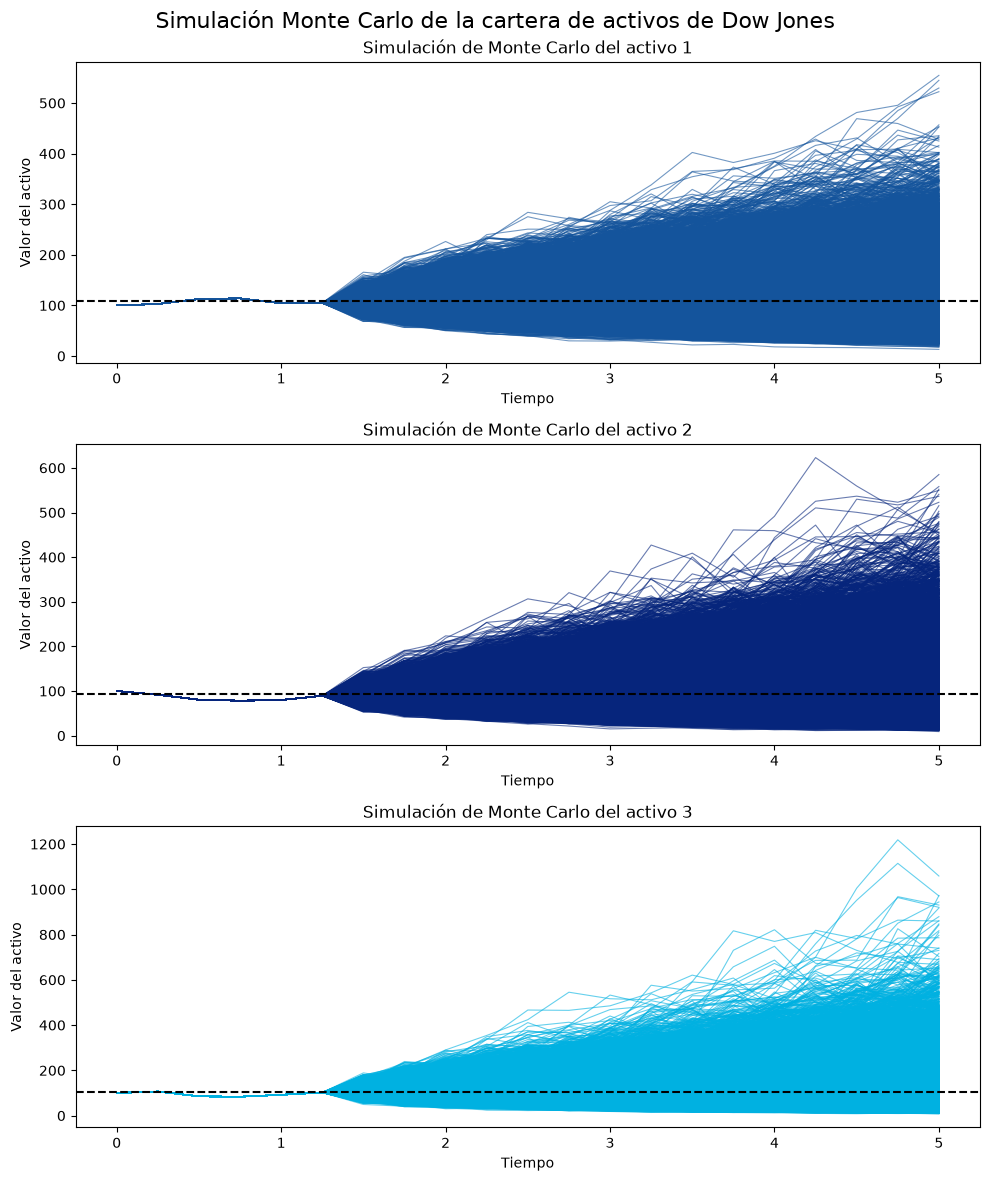

In [64]:
tiempo = np.linspace(0, T, n_times)

paleta_bbva = {
    "azul_logotipo": "#14549C",
    "azul_oscuro_digital": "#06257C",
    "azul_celeste_aqua": "#00B1E1"
}

colores = list(paleta_bbva.values())

fig, axes = plt.subplots(
    n_activos,
    1,
    figsize=(10, 4 * n_activos)
)

axes = np.atleast_1d(axes)

fig.suptitle(
    "Simulación Monte Carlo de la cartera de activos de Dow Jones",
    fontsize=16
)

_ = list(
    map(
        lambda p: (
            p[1].plot(
                tiempo,
                MC[:, :, p[0]].T,
                alpha = 0.6,
                linewidth = 0.8,
                color = colores[p[0] % len(colores)]
            ),
            p[1].set_title(f"Simulación de Monte Carlo de {p[0] + 1}"),
            p[1].set_xlabel("Tiempo"),
            p[1].set_ylabel("Valor del activo"),
            p[1].axhline(np.mean(MC[:, -1, p[0]]), linestyle = "--", linewidth = 1.5, color = 'black'),
        ),
        enumerate(axes)
    )
)

_ = list(
    map(
        lambda p: p[1].set_title(f"Simulación de Monte Carlo del activo {p[0] + 1}"),
        enumerate(axes)
    )
)

plt.tight_layout()
plt.show()